# 26 · A2A discovery: resolve a card, check it, match a skill
Level L4 · Part 4 · core · ~25 min · builds on 20, 25

## Goal
Find agents over A2A by their base addresses. A caller resolves each card from `/.well-known/agent-card.json`, checks the card is complete,
and matches its need to a skill. Two agents run on localhost for the lesson: an orders agent and a policy agent. The lesson makes no model call.

## Why it matters
Lesson 20 found agents in folders. Over the network a card can be wrong, incomplete or from a stranger. A caller that trusts any card sends
its requests to whatever address the card names, with whatever data the card asks for. Discovery over A2A is a lookup plus checks.

| Trust any card | Check the card |
|---|---|
| The skill is assumed to exist | The skill is listed in the card, with its input |
| The address in the card is used as written | The address is checked against the base the caller resolved |
| A missing field breaks the call later | A missing field is reported before the first call |

**What it makes easy:** a caller that can tell a good card from a broken one before it sends a task. **When you don't need it:** one agent you
run yourself.

## The idea
Discovery is three steps. **Resolve**: GET the card from a base address. **Check**: the card has a name, at least one skill, and skills with ids
and tags, and its interface URL is the base the caller used. **Match**: pick the agent whose skill fits the need. The card decides what the
caller sends; the caller never guesses.

## Picture
The diagram below is drawn by `show_mermaid`, a helper from the topic's `graph_view.py` that renders Mermaid text as a picture in the notebook.

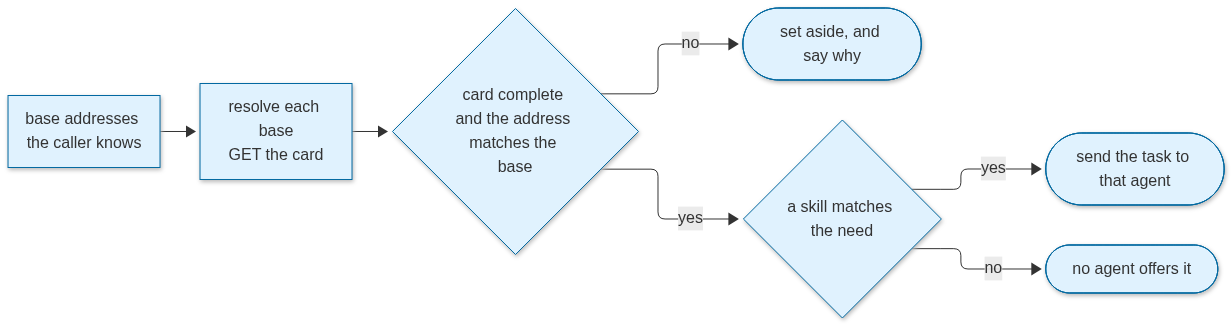

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py, a2a_server.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  B["base addresses the caller knows"] --> R["resolve each base<br/>GET the card"]
  R --> C{"card complete and the address matches the base"}
  C -->|no| X(["set aside, and say why"])
  C -->|yes| M{"a skill matches the need"}
  M -->|yes| G(["send the task to that agent"])
  M -->|no| N(["no agent offers it"])
  classDef code fill:#e0f2fe,stroke:#0369a1
  class B,R,C,X,M,G,N code
""")

## Step by step
Each step is a short explanation, then a code cell, then its printed output. Steps 1, 2 and 5 call local agents over HTTP; no model is called.

**Step 1 · two agents on localhost (no call).** An orders agent answers order status, and a policy agent answers policy questions. Three helpers
come from the topic's `a2a_server.py`: `serve` starts one agent on a free localhost port and returns its base address and its server, `stop`
shuts a server down, and `send_text` sends one text message to an agent and returns the events it sends back. The agent's executor is the
class below: it answers with a fixed text, which is enough to show discovery and the task flow.

In [2]:
from a2a.server.agent_execution import AgentExecutor
from a2a.server.tasks import TaskUpdater
from a2a.helpers import new_task_from_user_message, new_text_part
from a2a_server import serve, stop, send_text
import httpx

The executor is the part of an agent that answers a task. `CannedExecutor` subclasses the SDK's `AgentExecutor` base class and returns the same
reply every time, so the lesson can focus on discovery.

In [3]:
class CannedExecutor(AgentExecutor):
    """Answers with a fixed text: enough to show discovery and the task flow."""

    def __init__(self, reply: str):
        self.reply = reply

    async def execute(self, context, event_queue):
        task = context.current_task or new_task_from_user_message(context.message)
        if not context.current_task:
            await event_queue.enqueue_event(task)
        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work()
        await updater.add_artifact([new_text_part(self.reply)], name="answer")
        await updater.complete()

    async def cancel(self, context, event_queue):
        raise NotImplementedError

Start the two agents. Each `serve` call returns the agent's base address, which the caller will resolve in Step 2, and its server handle, which
`stop` needs at the end.

In [4]:
orders_base, orders_server = serve("orders-agent", "Order status questions.",
                                   [("order_status", "Order status", "Status of one order by its number.")],
                                   CannedExecutor("Order 1003 is lost, 9 days late."))
policy_base, policy_server = serve("policy-agent", "Refund, return and delivery policy questions.",
                                   [("policy_answer", "Policy answer", "Answers one policy question.")],
                                   CannedExecutor("Refunds need a person's approval; returns within 30 days."))
KNOWN_BASES = [orders_base, policy_base, "http://127.0.0.1:1"]  # the third address has no agent: discovery must cope
print("bases:", KNOWN_BASES[:2], "and one with no agent")

bases: ['http://127.0.0.1:33189', 'http://127.0.0.1:39997'] and one with no agent


**Step 2 · resolve each base (no call).** `resolve` GETs the card from the well-known path. A base with no agent does not answer; the caller
records the failure and moves on, instead of stopping the whole discovery.

In [5]:
async def resolve(base: str) -> dict | None:
    try:
        async with httpx.AsyncClient(timeout=2.0) as http:
            response = await http.get(base + "/.well-known/agent-card.json")
            response.raise_for_status()
            return response.json()
    except httpx.HTTPError as error:
        print(f"no card from {base}: {type(error).__name__}")
        return None


cards = {}
for base in KNOWN_BASES:
    card = await resolve(base)
    if card:
        cards[base] = card
print("resolved:", {card["name"]: base for base, card in cards.items()})

no card from http://127.0.0.1:1: ConnectError
resolved: {'orders-agent': 'http://127.0.0.1:33189', 'policy-agent': 'http://127.0.0.1:39997'}


**Step 3 · check each card (no call).** A card is used only if it passes the checks: a name, at least one skill, every skill with an id and a
tag, and an interface address that starts with the base the caller resolved. A card that fails is set aside, with the reason.

In [6]:
def check_card(base: str, card: dict) -> list[str]:
    problems = []
    if not card.get("name"):
        problems.append("no name")
    if not card.get("skills"):
        problems.append("no skills")
    for skill in card.get("skills", []):
        if not skill.get("id"):
            problems.append("a skill has no id")
        if not skill.get("tags"):
            problems.append(f"skill {skill.get('id')!r} has no tags")
    interfaces = card.get("supportedInterfaces") or card.get("supported_interfaces") or []
    if not any(i.get("url", "").startswith(base) for i in interfaces):
        problems.append("the interface address does not match the base")
    return problems


usable = {}
for base, card in cards.items():
    problems = check_card(base, card)
    if problems:
        print(f"set aside {card['name']}: {problems}")
    else:
        usable[base] = card
print("usable:", [card["name"] for card in usable.values()])

usable: ['orders-agent', 'policy-agent']


A card that names another address fails the check. Here the orders card is copied and its interface is pointed at `example.com`: the check
reports the reason, and the caller would never send a task there.

In [7]:
moved = dict(cards[orders_base])
moved["supportedInterfaces"] = [{"url": "http://example.com/agent"}]
print(check_card(orders_base, moved))

['the interface address does not match the base']


**Step 4 · match the need to a skill (no call).** The caller has a need. `find_skill` searches the usable cards for a skill with that id, and
returns the base and the skill. If none offers it, it returns `None`, and the caller reports that no agent offers the need.

In [8]:
def find_skill(need: str) -> tuple[str, dict] | None:
    for base, card in usable.items():
        for skill in card["skills"]:
            if skill["id"] == need:
                return base, skill
    return None


print(find_skill("policy_answer"))
print(find_skill("refund_order"))

('http://127.0.0.1:39997', {'id': 'policy_answer', 'name': 'Policy answer', 'description': 'Answers one policy question.', 'tags': ['policy_answer']})
None


**Step 5 · send the task to the matched agent (no call).** The matched base is used for the task with `send_text`. The reply comes back as an
artifact, and the caller reads the final state of the task from the events.

In [9]:
from a2a.types import a2a_pb2

match = find_skill("policy_answer")
if match:
    base, skill = match
    events = await send_text(base, "What is the refund policy?")
    for event in events:
        if event.HasField("task"):
            print("state:", a2a_pb2.TaskState.Name(event.task.status.state), "→", event.task.artifacts[0].parts[0].text)
stop(orders_server)
stop(policy_server)

state: TASK_STATE_COMPLETED → Refunds need a person's approval; returns within 30 days.


## At work
- A card is a claim by its owner. Teams check the card's address against the base they resolved, and they pin the card's version → lesson 27
  (A2A registry and delegation).
- A missing tag or a missing skill id is a card that some strict clients will refuse. The check catches it before the first call.
- Discovery through a list of bases is the same pattern as lesson 20. The new part is that the card comes over the network and can fail.

## What just happened
- Three bases were tried: two returned a card, and the base with no agent printed `ConnectError` and was skipped.
- Both cards passed `check_card`, so `usable` holds two agents. The copied card with the foreign address printed one problem: the interface
  address does not match the base.
- `find_skill("policy_answer")` returned the policy agent's base and skill; `find_skill("refund_order")` returned `None`.
- The task went to the policy agent and came back `TASK_STATE_COMPLETED`, with the policy text as the artifact.

## Common mistakes
1. **Stopping on the first unreachable base.** One agent being down should not stop discovery of the others. The cell below shows the error a
   caller sees with no handling; `resolve` records it and goes on.
2. **Trusting the interface address.** A card can name any address. Step 3 printed the check catching a card that pointed elsewhere; check it
   against the base you resolved.
3. **Matching on the name.** Names change; the skill id is the contract the caller relies on. The cell below looks an agent up by a new name
   and gets a `KeyError`.

In [10]:
# mistake 1: no try/except around an unreachable base
try:
    async with httpx.AsyncClient(timeout=2.0) as http:
        await http.get("http://127.0.0.1:1/.well-known/agent-card.json")
except httpx.HTTPError as error:
    print(f"mistake 1: {type(error).__name__}: {str(error).splitlines()[0]}")

mistake 1: ConnectError: All connection attempts failed


The fix is the `try/except` in `resolve` (Step 2): the failure is recorded and the loop goes on. Mistake 3 is next; its fix is to match on the skill id.

In [11]:
# mistake 3: the owner renames the agent, and the caller still looks it up by the old name
by_name = {card["name"]: base for base, card in usable.items()}
try:
    by_name["policy-desk"]
except KeyError as error:
    print(f"mistake 3: {type(error).__name__}: {error}")

mistake 3: KeyError: 'policy-desk'


## Try it
Write `usable_names(cards)` that takes the `cards` dict from Step 2 and returns the sorted names of the cards that pass `check_card`. Test it on
`cards`. No model call is needed.

In [12]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [13]:
def usable_names(cards: dict) -> list[str]:
    return sorted(card["name"] for base, card in cards.items() if not check_card(base, card))


print(usable_names(cards))  # ['orders-agent', 'policy-agent']

['orders-agent', 'policy-agent']


## Key terms
- **Base address** — the address of an agent's server, such as `http://127.0.0.1:37993`; the card is fetched from it.
- **Resolve** — GET the agent card from the base address's well-known path, and record the failure if no card comes back.
- **Check** — test the card for a name, skills with ids and tags, and an interface address that matches the base.
- **Skill id** — the id of one skill in a card; the caller matches on it, not on the agent's name.
- **Artifact** — an output an agent attaches to a task, such as the text of an answer.

## Recap
- Discovery over A2A resolves each base address to its card, then checks the card.
- A card that fails a check is set aside with its reason; an unreachable base is recorded and skipped.
- The skill id decides the match, and the matched base receives the task.

**Interview:** "A new agent is announced to you by its address. How do you decide whether to send it customer data?" Strong answer: "I fetch its
card from the address, check the card is complete and points back to that address, and only then match a skill. Sending customer data is a
separate decision, which needs the agent to be on the allow-list."